# Scribal Identification — Clustering Comparison & Meta-Clustering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LogNorm
import seaborn as sns
from sklearn.metrics import (adjusted_rand_score, adjusted_mutual_info_score,
                             pair_confusion_matrix)
from itertools import combinations
import plotly.graph_objects as go
import plotly.colors as pc

sns.set_style("whitegrid")
mpl.rcParams['figure.dpi'] = 120
mpl.rcParams['figure.figsize'] = (10, 6)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Roboto Condensed']

In [2]:
df = pd.read_excel('../data/misc-assets/clusterings.xlsx')
print(f"Corpus size: {len(df)} documents")
df.rename(columns={'HDBSCAN': 'CUSTOM'}, inplace=True)
df.rename(columns={'cluster_id_L1': 'RAVEN'}, inplace=True)
df.rename(columns={'group-adjusted': 'human-final'}, inplace=True)
df.rename(columns={'group-warmup': 'human-warmup'}, inplace=True)
df.head()

Corpus size: 470 documents


,id,filename,RAVEN,CUSTOM,human-warmup,human-final
0,01_01_1332-01,0001_01_01_1332-01.jpg,0,-1.0,Y,R
1,01_01_1335-01,0002_01_01_1335-01.jpg,0,-1.0,Y,R
2,01_01_1346-01,0003_01_01_1346-01.jpg,13,0.0,M,Q
3,01_01_1349-01,0004_01_01_1349-01.jpg,21,-1.0,Q,P
4,01_02_1341-01,0005_01_02_1341-01.jpg,15,7.0,Y,R


## 1. Overview clusterings

In [3]:
clustering_cols = ['human-warmup', 'RAVEN', 'CUSTOM', 'human-final']

summary_rows = []
for col in clustering_cols:
    s = df[col]
    non_null = s.dropna()
    if non_null.dtype == object:
        noise = (non_null.astype(str) == '-1').sum()
    else:
        noise = (non_null == -1).sum()
    assigned = non_null[~non_null.astype(str).isin(['-1', '-1.0'])]
    n_clusters = assigned.nunique()
    missing = s.isna().sum()

    # Cluster size stats
    if len(assigned) > 0:
        sizes = assigned.astype(str).value_counts()
        mean_size = sizes.mean()
        median_size = sizes.median()
        min_size = sizes.min()
        max_size = sizes.max()
    else:
        mean_size = median_size = min_size = max_size = float('nan')

    origin = 'human' if 'human' in col else 'computational'

    summary_rows.append({
        'clustering': col,
        'origin': origin,
        'n_clusters': n_clusters,
        'n_noise_missing': noise + missing,
        'mean_size': mean_size,
        'median_size': median_size,
        'min_size': min_size,
        'max_size': max_size,
    })

summary = pd.DataFrame(summary_rows)

# LaTeX table
lines = []
lines.append(r'\begin{table}[t]')
lines.append(r'\centering')
lines.append(r'\footnotesize')
lines.append(r'\caption{Summary statistics on the 4 clusterings available (two human, two computational).}')
lines.append(r'\label{tab:clustering-summary}')
lines.append(r'\begin{tabular}{llrrrrrr}')
lines.append(r'\toprule')
lines.append(r'Clustering & Origin & $k$ & Unassigned & Mean & Median & Min & Max \\')
lines.append(r'\midrule')
for _, row in summary.iterrows():
    lines.append(
        f"{row['clustering']} & {row['origin']} & {row['n_clusters']} & "
        f"{row['n_noise_missing']} & {row['mean_size']:.1f} & "
        f"{row['median_size']:.0f} & {row['min_size']:.0f} & {row['max_size']:.0f} \\\\"
    )
lines.append(r'\bottomrule')
lines.append(r'\end{tabular}')
lines.append(r'\label{tab:clusters}')
lines.append(r'\end{table}')

latex_table = '\n'.join(lines)
print(latex_table)

\begin{table}[t]
\centering
\footnotesize
\caption{Summary statistics on the 4 clusterings available (two human, two computational).}
\label{tab:clustering-summary}
\begin{tabular}{llrrrrrr}
\toprule
Clustering & Origin & $k$ & Unassigned & Mean & Median & Min & Max \\
\midrule
human-warmup & human & 23 & 75 & 17.2 & 7 & 2 & 189 \\
RAVEN & computational & 25 & 0 & 18.8 & 17 & 4 & 58 \\
CUSTOM & computational & 19 & 46 & 22.3 & 18 & 11 & 48 \\
human-final & human & 13 & 20 & 34.6 & 14 & 2 & 217 \\
\bottomrule
\end{tabular}
\label{tab:clusters}
\end{table}


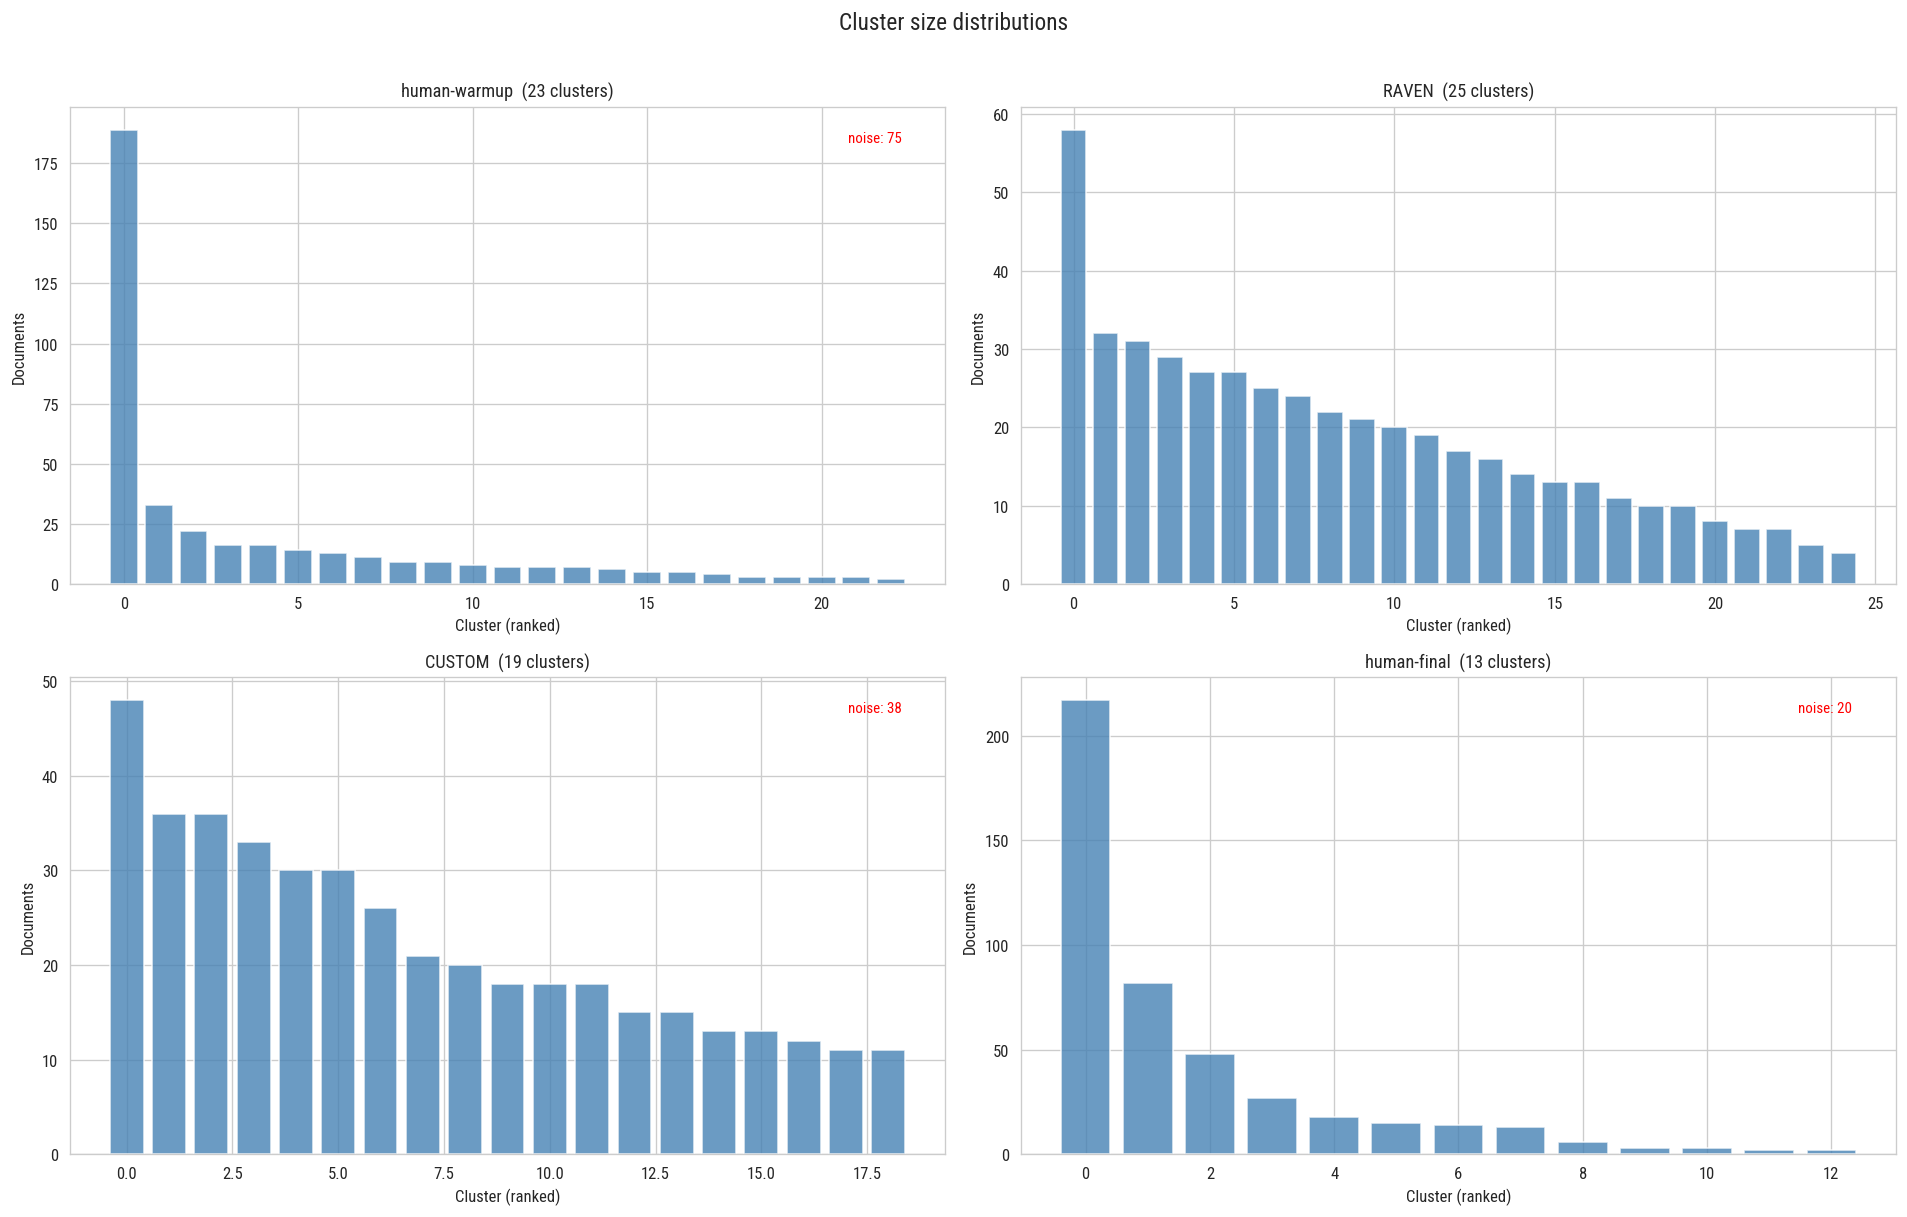

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, col in enumerate(clustering_cols):
    ax = axes[i]
    s = df[col].dropna()

    # Exclude noise for the distribution plot
    if s.dtype == object:
        assigned = s[s.astype(str) != '-1']
    else:
        assigned = s[s != -1]
    counts = assigned.value_counts().sort_values(ascending=False)
    ax.bar(range(len(counts)), counts.values, color='steelblue', alpha=0.8)
    ax.set_title(f'{col}  ({len(counts)} clusters)', fontsize=11)
    ax.set_xlabel('Cluster (ranked)')
    ax.set_ylabel('Documents')
    
    # Annotate noise count
    noise_n = len(s) - len(assigned)
    if noise_n > 0:
        ax.annotate(f'noise: {noise_n}', xy=(0.95, 0.95), xycoords='axes fraction',
                     ha='right', va='top', fontsize=9, color='red')

plt.suptitle('Cluster size distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/cluster_sizes.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Pairwise comparison of clusterings

For each pair of clusterings we compute:
- **Adjusted Rand Index (ARI)**: agreement corrected for chance; 1 = perfect, 0 = chance, <0 = worse than chance.
- **Normalized Mutual Information (NMI)**: shared information; 1 = identical, 0 = independent.
- **Match**: fraction of document pairs assigned consistently (together/apart) in both clusterings.

The results are reported in a single **joint table** under two treatments of HDBSCAN noise (`-1`):
the left block keeps **noise as a separate class**, while the right block **ignores noise completely**
(every `-1` document is dropped per pair before scoring). Both blocks are built from the same base
population, so they differ only in how the `-1` label is handled. The emitted LaTeX therefore has
its data columns doubled — the four metrics ($n$, ARI, NMI, Match) appear once per treatment.


In [5]:
clustering_cols = ['CUSTOM', 'human-warmup', 'human-final', 'RAVEN']
NOISE_AS_CLASS = True

def clean_labels(series, noise_as_class=False):
    """Mask of usable docs + the series. NaN is always dropped.
    -1 (HDBSCAN noise) is dropped only when noise_as_class=False; otherwise it
    is kept and treated as an ordinary cluster label."""
    s = series.copy()
    mask = s.notna()
    if not noise_as_class:                      # only drop -1 when NOT treating it as a class
        if s.dtype == object:
            mask = mask & (s.astype(str) != '-1')
        else:
            mask = mask & (s != -1)
    return mask, s

mask = np.logical_and.reduce(
    [clean_labels(df[c], NOISE_AS_CLASS)[0] for c in clustering_cols]
)
df = df[mask]

print(f"{mask.sum()} / {len(df)} rows usable across all "
      f"{len(clustering_cols)} clusterings "
      f"({'noise = class' if NOISE_AS_CLASS else 'noise dropped'})")

462 / 462 rows usable across all 4 clusterings (noise = class)


In [6]:
clustering_cols = ['CUSTOM', 'human-warmup', 'human-final', 'RAVEN']


def compute_pairwise_scores(df, cols, noise_as_class):
    """Per-pair ARI / NMI / Match for every pair of clusterings under a single
    noise treatment. Returns a tidy DataFrame with one row per pair."""
    results = []
    for c1, c2 in combinations(cols, 2):
        m1, s1 = clean_labels(df[c1], noise_as_class)
        m2, s2 = clean_labels(df[c2], noise_as_class)
        both = m1 & m2
        n = int(both.sum())
        if n < 10:
            results.append({'A': c1, 'B': c2, 'n_shared': n,
                            'ARI': np.nan, 'NMI': np.nan, 'match_frac': np.nan})
            continue

        a = s1[both].astype(str).values
        b = s2[both].astype(str).values

        ari = adjusted_rand_score(a, b)
        nmi = adjusted_mutual_info_score(a, b, average_method='arithmetic')
        pcm = pair_confusion_matrix(a, b)
        match_frac = (pcm[0, 0] + pcm[1, 1]) / pcm.sum()

        results.append({'A': c1, 'B': c2, 'n_shared': n,
                        'ARI': ari, 'NMI': nmi, 'match_frac': match_frac})
    return pd.DataFrame(results)


def joint_pairwise_latex(df, cols, sort_block='noise_as_class'):
    """Compute BOTH noise treatments and emit ONE joint LaTeX table whose data
    columns are doubled: a "noise as separate class" block (-1 kept as its own
    label) and a "noise ignored" block (-1 completely dropped per pair), sharing
    the pair identifiers (A, B).

    sort_block : 'noise_as_class' or 'noise_ignored' -- which block's ARI orders
                 the rows. Rows stay aligned across both blocks either way.
    """
    s_class  = compute_pairwise_scores(df, cols, noise_as_class=True)   # noise = own class
    s_ignore = compute_pairwise_scores(df, cols, noise_as_class=False)  # noise dropped

    # one row per pair, both treatments side by side
    merged = s_class.merge(s_ignore, on=['A', 'B'], suffixes=('_wn', '_nn'))
    sort_key = 'ARI_wn' if sort_block == 'noise_as_class' else 'ARI_nn'
    merged = merged.sort_values(sort_key, ascending=False).reset_index(drop=True)

    EOL = r' \\'                       # LaTeX end-of-row

    def f3(x):
        return '--' if pd.isna(x) else f'{x:.3f}'

    def f0(x):
        return '--' if pd.isna(x) else f'{x:.0f}'

    lines = []
    lines.append(r'\begin{table}[t]')
    lines.append(r'\centering')
    lines.append(r'\footnotesize')
    lines.append(r'\caption{Pairwise agreement between clusterings, reported jointly under two '
                 r'treatments of HDBSCAN noise ($-1$): \emph{noise as a separate class} (left '
                 r'block) and \emph{noise completely ignored} (right block). Agreement is measured '
                 r'by the Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), and the '
                 r'fraction of document pairs assigned consistently (Match). $n$ is the number of '
                 r'documents with valid labels in both clusterings under that treatment.}')
    lines.append(r'\label{tab:pairwise-agreement}')
    lines.append(r'\begin{tabular}{ll rrrr rrrr}')
    lines.append(r'\toprule')
    lines.append(r'& & \multicolumn{4}{c}{Noise as separate class} '
                 r'& \multicolumn{4}{c}{Noise ignored}' + EOL)
    lines.append(r'\cmidrule(lr){3-6} \cmidrule(lr){7-10}')
    lines.append(r'A & B & $n$ & ARI & NMI & Match & $n$ & ARI & NMI & Match' + EOL)
    lines.append(r'\midrule')
    for _, r in merged.iterrows():
        lines.append(
            f"{r['A']} & {r['B']} & "
            f"{f0(r['n_shared_wn'])} & {f3(r['ARI_wn'])} & {f3(r['NMI_wn'])} & {f3(r['match_frac_wn'])} & "
            f"{f0(r['n_shared_nn'])} & {f3(r['ARI_nn'])} & {f3(r['NMI_nn'])} & {f3(r['match_frac_nn'])}"
            + EOL
        )
    lines.append(r'\bottomrule')
    lines.append(r'\end{tabular}')
    lines.append(r'\end{table}')

    print('\n'.join(lines))
    return merged, s_class, s_ignore


joint_scores, scores_noise_as_class, scores_noise_ignored = joint_pairwise_latex(
    df, clustering_cols, sort_block='noise_as_class')

# Keep `scores` as the noise-as-class variant so the heatmap cell below is unchanged.
scores = scores_noise_as_class

\begin{table}[t]
\centering
\footnotesize
\caption{Pairwise agreement between clusterings, reported jointly under two treatments of HDBSCAN noise ($-1$): \emph{noise as a separate class} (left block) and \emph{noise completely ignored} (right block). Agreement is measured by the Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), and the fraction of document pairs assigned consistently (Match). $n$ is the number of documents with valid labels in both clusterings under that treatment.}
\label{tab:pairwise-agreement}
\begin{tabular}{ll rrrr rrrr}
\toprule
& & \multicolumn{4}{c}{Noise as separate class} & \multicolumn{4}{c}{Noise ignored} \\
\cmidrule(lr){3-6} \cmidrule(lr){7-10}
A & B & $n$ & ARI & NMI & Match & $n$ & ARI & NMI & Match \\
\midrule
human-warmup & human-final & 462 & 0.512 & 0.471 & 0.826 & 380 & 0.654 & 0.587 & 0.863 \\
CUSTOM & RAVEN & 462 & 0.441 & 0.591 & 0.941 & 424 & 0.513 & 0.643 & 0.948 \\
CUSTOM & human-final & 462 & 0.224 & 0.589 & 0.775 & 407 & 0.270

In [7]:
# In-notebook view of the same joint table, columns grouped by noise treatment.
_disp = joint_scores.copy()
_disp.columns = pd.MultiIndex.from_tuples([
    ('',                        'A'),
    ('',                        'B'),
    ('noise as separate class', 'n'),
    ('noise as separate class', 'ARI'),
    ('noise as separate class', 'NMI'),
    ('noise as separate class', 'Match'),
    ('noise ignored',           'n'),
    ('noise ignored',           'ARI'),
    ('noise ignored',           'NMI'),
    ('noise ignored',           'Match'),
])
_disp.round(3)


noise as separate class                       \
              A             B                       n    ARI    NMI  Match   
0  human-warmup   human-final                     462  0.512  0.471  0.826   
1        CUSTOM         RAVEN                     462  0.441  0.591  0.941   
2        CUSTOM   human-final                     462  0.224  0.589  0.775   
3   human-final         RAVEN                     462  0.209  0.541  0.773   
4  human-warmup         RAVEN                     462  0.156  0.323  0.806   
5        CUSTOM  human-warmup                     462  0.140  0.340  0.800   

  noise ignored                       
              n    ARI    NMI  Match  
0           380  0.654  0.587  0.863  
1           424  0.513  0.643  0.948  
2           407  0.270  0.637  0.784  
3           444  0.210  0.557  0.759  
4           390  0.176  0.392  0.775  
5           355  0.192  0.444  0.782

/var/folders/6j/pn9nz6b55j3fpdt8gtj50crm0000gn/T/ipykernel_77031/3173732766.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1])


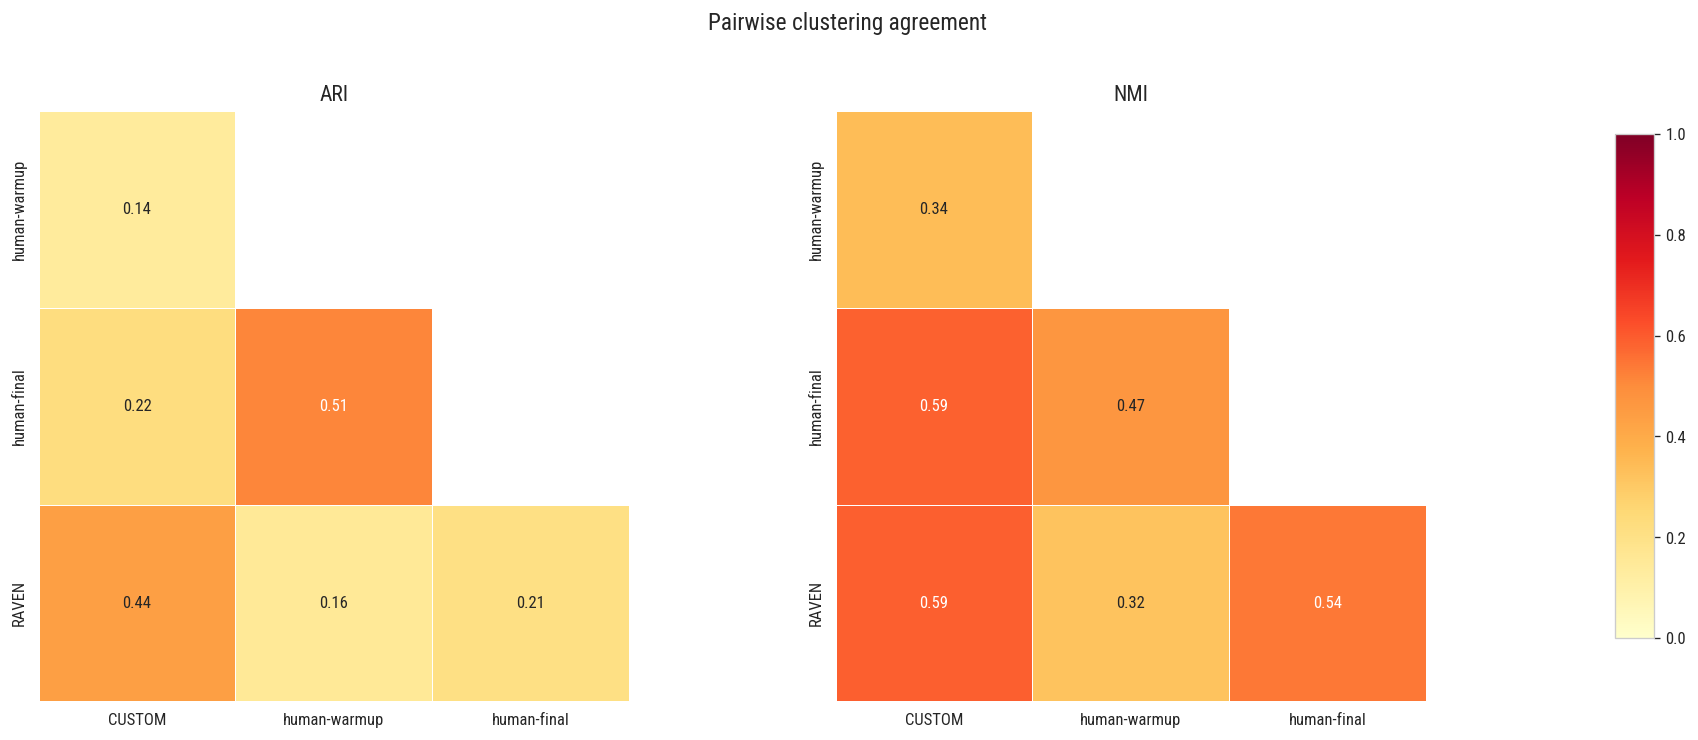

In [8]:
def to_matrix(scores_df, metric):
    labels = clustering_cols
    mat = pd.DataFrame(1.0 if metric in ('ARI','NMI') else 0,
                       index=labels, columns=labels)
    for _, row in scores_df.iterrows():
        mat.loc[row['A'], row['B']] = row[metric]
        mat.loc[row['B'], row['A']] = row[metric]
    return mat

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
norm = plt.Normalize(vmin=0, vmax=1)
cmap = plt.cm.YlOrRd

for ax, metric, title in zip(axes, ['ARI', 'NMI'], ['ARI', 'NMI']):
    mat = to_matrix(scores, metric)
    mask = np.triu(np.ones_like(mat, dtype=bool), k=0)
    mat = mat.iloc[1:, :-1]
    mask = mask[1:, :-1]

    sns.heatmap(mat, annot=True, fmt='.2f', cmap=cmap, norm=norm,
            mask=mask, ax=ax, square=True, linewidths=0.5,
            linecolor='white', cbar=False)
    ax.grid(False)
    ax.set_title(title, fontsize=13)

fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax)

plt.suptitle('Pairwise clustering agreement', fontsize=14, y=1.02)
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig('../outputs/cluster_comp.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Sankey diagrams

In [9]:
def two_way_sankey(df, left_col, right_col,
                   left_prefix='L', right_prefix='R',
                   noise_label='noise', title=None,
                   width=900, height=700):
    sub = df[[left_col, right_col]].dropna().copy()

    def _label(val, prefix):
        try:
            num = float(val)
            if num == int(num):
                val = int(num)
            return f'{prefix}-{noise_label}' if val == -1 else f'{prefix}{val}'
        except (ValueError, TypeError):
            return f'{prefix}-{val}'

    sub['_left']  = sub[left_col].map(lambda x: _label(x, left_prefix))
    sub['_right'] = sub[right_col].map(lambda x: _label(x, right_prefix))

    ct = pd.crosstab(sub['_left'], sub['_right'])
    flows = [(l, r, int(ct.loc[l, r]))
             for l in ct.index for r in ct.columns if ct.loc[l, r] > 0]

    def _sort_key(x, prefix):
        stripped = x.replace(f'{prefix}-', '').replace(prefix, '')
        try:
            return float(stripped)
        except ValueError:
            return float('inf')

    left_labels  = sorted(ct.index,   key=lambda x: _sort_key(x, left_prefix))
    right_labels = sorted(ct.columns, key=lambda x: _sort_key(x, right_prefix))
    all_labels   = left_labels + right_labels
    label_to_idx = {l: i for i, l in enumerate(all_labels)}

    source = [label_to_idx[f[0]] for f in flows]
    target = [label_to_idx[f[1]] for f in flows]
    value  = [f[2] for f in flows]

    palette = pc.qualitative.Pastel * 3
    node_colors = ([palette[i % len(palette)] for i in range(len(left_labels))]
                   + ['rgba(140,140,140,0.7)'] * len(right_labels))

    def _to_rgba(rgb_str, alpha=0.3):
        return rgb_str.replace('rgb', 'rgba').replace(')', f',{alpha})')

    link_colors = [_to_rgba(palette[left_labels.index(f[0]) % len(palette)])
                   for f in flows]

    node_label_text = [
        f'{l} ({ct.loc[l].sum()})' if l in left_labels else f'{l} ({ct[l].sum()})'
        for l in all_labels
    ]

    fig = go.Figure(go.Sankey(
        node=dict(pad=8, thickness=16,
                  line=dict(color='rgba(0,0,0,0.3)', width=0.5),
                  label=node_label_text, color=node_colors),
        link=dict(source=source, target=target, value=value, color=link_colors),
    ))

    fig.update_layout(
        title_text=title or f'{left_col} → {right_col}',
        font=dict(size=11), width=width, height=height,
        margin=dict(l=10, r=10, t=40, b=20),
    )
    fig.show()

#### Sankey diagram: HDBSCAN vs group-final

In [10]:
two_way_sankey(df, 'CUSTOM', 'human-final',
               left_prefix='H', right_prefix='G',
               title='CUSTOM clusters → Expert hands (group-final)')

In [11]:
two_way_sankey(df, 'RAVEN', 'human-final',
               left_prefix='H', right_prefix='G',
               title='RAVEN → Expert hands (group-final)')

In [12]:
two_way_sankey(df, 'human-warmup', 'human-final',
               left_prefix='H', right_prefix='G',
               title='CUSTOM → Expert hands (group-final)')

In [13]:
two_way_sankey(df, 'RAVEN', 'CUSTOM',
               left_prefix='H', right_prefix='G',
               title='RAVEN → CUSTOM')

In [14]:
# ── LEFT flows: custom -> human ───────────────────────────────────
mask_hg = df['CUSTOM'].notna() & df['human-final'].notna()
sub_hg = df[mask_hg].copy()
sub_hg['hdb'] = sub_hg['CUSTOM'].astype(int).map(
    lambda x: 'custom-noise' if x == -1 else f'custom-{x}')
sub_hg['hum'] = sub_hg['human-final'].astype(str).map(
    lambda x: 'human-noise' if x == '-1' else f'human-{x}')

ct_hg = pd.crosstab(sub_hg['hdb'], sub_hg['hum'])
flows_left = [(h, g, int(ct_hg.loc[h, g]))
              for h in ct_hg.index for g in ct_hg.columns
              if ct_hg.loc[h, g] > 0]

# ── RIGHT flows: human -> raven ───────────────────────────────────
mask_gl = df['human-final'].notna() & df['RAVEN'].notna()
sub_gl = df[mask_gl].copy()
sub_gl['hum'] = sub_gl['human-final'].astype(str).map(
    lambda x: 'human-noise' if x == '-1' else f'human-{x}')
sub_gl['rav'] = sub_gl['RAVEN'].astype(int).map(
    lambda x: 'raven-noise' if x == -1 else f'raven-{x}')

ct_gl = pd.crosstab(sub_gl['hum'], sub_gl['rav'])
flows_right = [(g, l, int(ct_gl.loc[g, l]))
               for g in ct_gl.index for l in ct_gl.columns
               if ct_gl.loc[g, l] > 0]

# ── node list: custom (left) | human (center) | raven (right)
hdb_labels = sorted(
    ct_hg.index,
    key=lambda x: -1 if 'noise' in x else int(x.split('-')[1]))
hum_labels = sorted(set(ct_hg.columns) | set(ct_gl.index))
rav_labels = sorted(
    ct_gl.columns,
    key=lambda x: -1 if 'noise' in x else int(x.split('-')[1]))

all_labels = hdb_labels + hum_labels + rav_labels
label_to_idx = {l: i for i, l in enumerate(all_labels)}

# ── counts per node ───────────────────────────────────────────────
node_counts = {}
for l in hdb_labels:
    node_counts[l] = ct_hg.loc[l].sum() if l in ct_hg.index else 0
for l in hum_labels:
    c = 0
    if l in ct_hg.columns: c = max(c, ct_hg[l].sum())
    if l in ct_gl.index:   c = max(c, ct_gl.loc[l].sum())
    node_counts[l] = c
for l in rav_labels:
    node_counts[l] = ct_gl[l].sum() if l in ct_gl.columns else 0

# ── link arrays ───────────────────────────────────────────────────
source = [label_to_idx[f[0]] for f in flows_left + flows_right]
target = [label_to_idx[f[1]] for f in flows_left + flows_right]
value  = [f[2] for f in flows_left + flows_right]

# ── x/y positions: proportional to flow volume ────────────────────
def proportional_y(labels, counts_dict):
    sizes = [counts_dict.get(l, 1) for l in labels]
    total = sum(sizes)
    positions = []
    cumulative = 0
    for s in sizes:
        positions.append((cumulative + s / 2) / total)
        cumulative += s
    return positions

node_x, node_y = [], []

hdb_sizes = {l: ct_hg.loc[l].sum() for l in hdb_labels}
for y in proportional_y(hdb_labels, hdb_sizes):
    node_x.append(0.01);  node_y.append(y)

hum_sizes = {}
for l in hum_labels:
    c = 0
    if l in ct_hg.columns: c += ct_hg[l].sum()
    if l in ct_gl.index:   c += ct_gl.loc[l].sum()
    hum_sizes[l] = c
for y in proportional_y(hum_labels, hum_sizes):
    node_x.append(0.50);  node_y.append(y)

rav_sizes = {l: ct_gl[l].sum() for l in rav_labels}
for y in proportional_y(rav_labels, rav_sizes):
    node_x.append(0.99);  node_y.append(y)

# ── colors ────────────────────────────────────────────────────────
n_hdb, n_hum, n_rav = len(hdb_labels), len(hum_labels), len(rav_labels)
pal_hdb = pc.qualitative.Set2 * 5
pal_hum = pc.qualitative.Set1 * 5
pal_rav = pc.qualitative.Pastel1 * 5

def to_rgba(rgb_str, alpha=0.3):
    return rgb_str.replace('rgb', 'rgba').replace(')', f',{alpha})')

node_colors = (
    [pal_hdb[i % len(pal_hdb)] for i in range(n_hdb)]
    + [pal_hum[i % len(pal_hum)] for i in range(n_hum)]
    + [pal_rav[i % len(pal_rav)] for i in range(n_rav)]
)

link_colors = (
    [to_rgba(pal_hdb[hdb_labels.index(f[0]) % len(pal_hdb)]) for f in flows_left]
    + [to_rgba(pal_hum[hum_labels.index(f[0]) % len(pal_hum)]) for f in flows_right]
)

display_labels = [f'{l} ({node_counts[l]})' for l in all_labels]

# ── sankey figure ─────────────────────────────────────────────────
fig = go.Figure(go.Sankey(
    arrangement='snap',
    node=dict(
        pad=6, thickness=16,
        line=dict(color='rgba(0,0,0,0.3)', width=0.5),
        label=display_labels,
        color=node_colors,
        x=node_x, y=node_y,
    ),
    link=dict(source=source, target=target, value=value, color=link_colors),
))

fig.update_layout(
    #title_text='hdbscan  →  human  →  raven',
    font=dict(size=10),
    width=1200, height=800,
    margin=dict(l=10, r=10, t=40, b=20),
)

for x_pos, label in [(0.01, 'CUSTOM'), (0.50, 'human-final'), (0.99, 'RAVEN')]:
    fig.add_annotation(
        x=x_pos, y=1.06, xref='paper', yref='paper',
        text=f'<b>{label}</b>', showarrow=False, font=dict(size=14),
    )

fig.show()

## 4. Temporal ranges

In [15]:
# ── parse dates from IDs ──────────────────────────────────────────
parts = df['id'].str.extract(r'_(\d{2})_(\d{4})-')
parts.columns = ['month', 'year']
df['date_year'] = pd.to_numeric(parts['year'], errors='coerce')
df['date_month'] = pd.to_numeric(parts['month'], errors='coerce').fillna(6)
df['date_frac'] = df['date_year'] + (df['date_month'] - 0.5) / 12

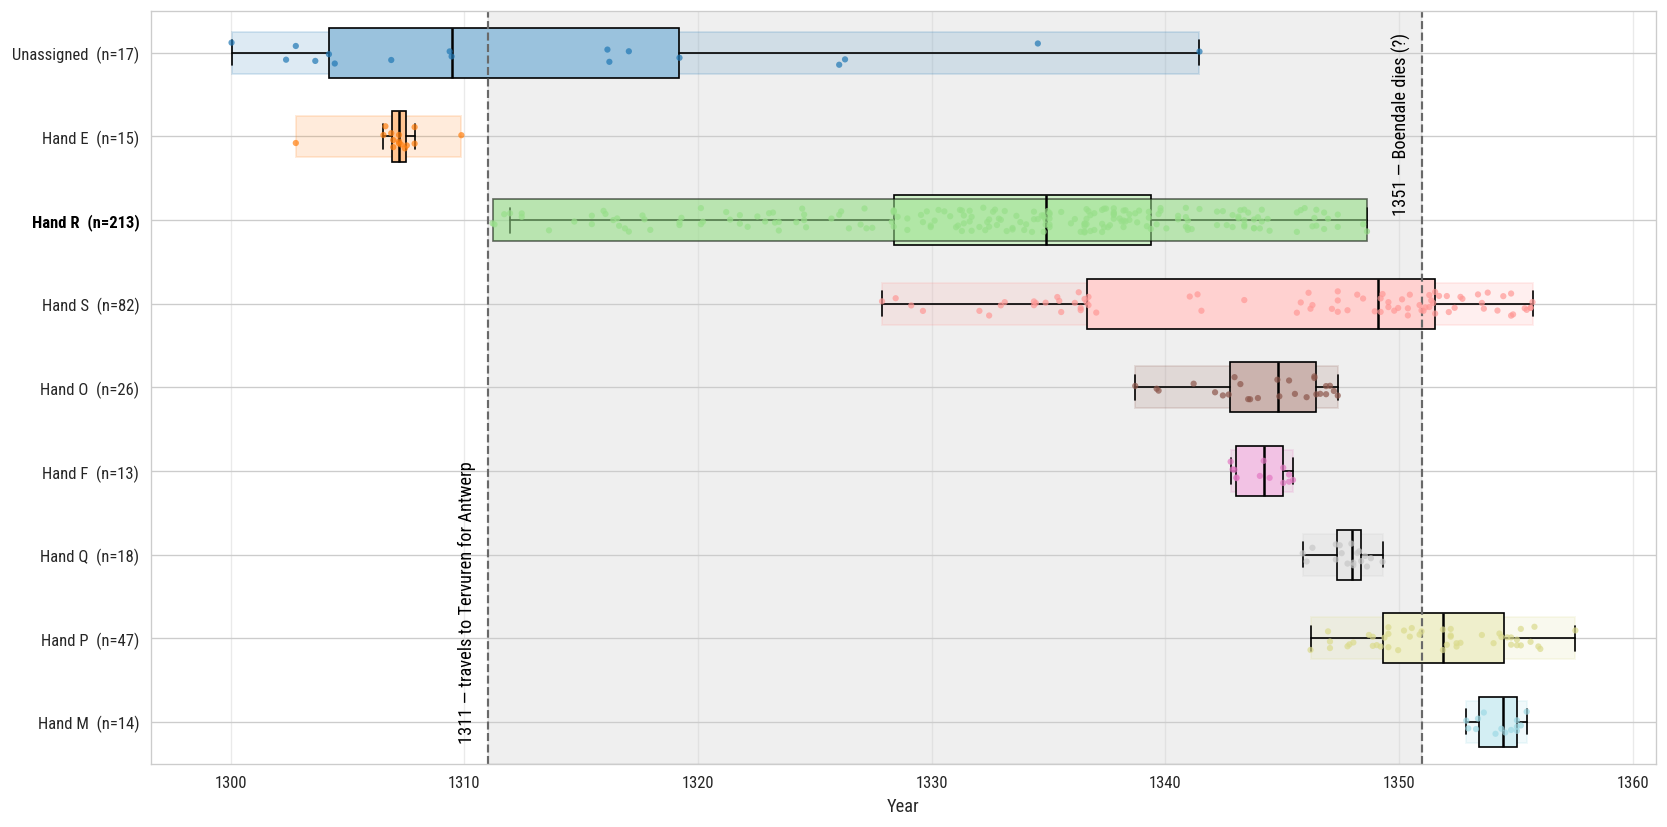

In [16]:
import matplotlib.colors as mcolors
# assumes `df` already exists in the notebook

def lighten(c, f=0.55):                 # blend a color toward white
    r, g, b = mcolors.to_rgb(c)
    return (r + (1 - r) * f, g + (1 - g) * f, b + (1 - b) * f)

# ── data prep ─────────────────────────────────────────────────────
label_col = 'human-final'
sub = df.dropna(subset=['date_frac', label_col]).copy()
sub['label'] = sub[label_col].astype(str)

keep = sub['label'].value_counts()
min_docs = 10
keep = keep[keep >= min_docs].index
sub = sub[sub['label'].isin(keep)]

cluster_stats = []
for lab, grp in sub.groupby('label'):
    cluster_stats.append({
        'label': lab,
        'n': len(grp),
        'frac_min': grp['date_frac'].min(),
        'frac_max': grp['date_frac'].max(),
        'frac_median': grp['date_frac'].median(),
    })
cs = pd.DataFrame(cluster_stats).sort_values('frac_min')
order = cs['label'].tolist()

# ── reference window: 1311–1351 ───────────────────────────────────
win_lo, win_hi = 1311, 1351

def hand_name(lab):                     # display name for the y-axis
    return 'Unassigned' if lab == '-1' else f'Hand {lab}'

# ── plot ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
colors = plt.cm.tab20(np.linspace(0, 1, len(cs)))

box_data = [sub[sub['label'] == lab]['date_frac'].values for lab in order]
bp = ax.boxplot(box_data, vert=False, patch_artist=True,
                showfliers=False, widths=0.6)

# grey window band (stays at the very bottom of the z-stack)
ax.axvspan(win_lo, win_hi, color='0.5', alpha=0.12, zorder=0)
for x in (win_lo, win_hi):
    ax.axvline(x, color='dimgrey', ls='--', lw=1.3, zorder=2)

# event labels: 1311 at bottom-left of its line, 1351 at top
trans = ax.get_xaxis_transform()        # x = data coords, y = axes fraction
ax.annotate('1311 — travels to Tervuren for Antwerp',
            xy=(win_lo, 0.01), xycoords=trans,
            xytext=(-7, 8), textcoords='offset points',
            rotation=90, va='bottom', ha='right', fontsize=11, color='black', zorder=5)
ax.annotate('1351 — Boendale dies (?)',
            xy=(win_hi, 0.99), xycoords=trans,
            xytext=(-7, -8), textcoords='offset points',
            rotation=90, va='top', ha='right', fontsize=11, color='black', zorder=5)

# bars / scatter
for i, (patch, color) in enumerate(zip(bp['boxes'], colors)):
    # opaque (lightened) box so the grey band reads as underneath it
    patch.set_facecolor(lighten(color))
    patch.set_alpha(1.0)
    patch.set_zorder(2)

    lab = order[i]
    grp = sub[sub['label'] == lab]
    y = i + 1

    # full span bar (min → max), kept translucent
    ax.barh(y, grp['date_frac'].max() - grp['date_frac'].min(),
            left=grp['date_frac'].min(), height=0.5,
            color=color, alpha=0.15, edgecolor=color, linewidth=1.2, zorder=1)

    # emphasise only Hand R: darken the part of its span inside the window
    if lab == 'R':
        seg_lo = max(grp['date_frac'].min(), win_lo)
        seg_hi = min(grp['date_frac'].max(), win_hi)
        if seg_hi > seg_lo:
            ax.barh(y, seg_hi - seg_lo, left=seg_lo, height=0.5,
                    color=color, alpha=0.55, edgecolor='black', linewidth=1.0, zorder=2.5)

    # jittered scatter
    jitter = np.random.default_rng(42).uniform(-0.15, 0.15, size=len(grp))
    ax.scatter(grp['date_frac'], y + jitter, s=14, color=color,
               alpha=0.7, zorder=3, edgecolors='none')

for median_line in bp['medians']:
    median_line.set_color('black')
    median_line.set_linewidth(1.5)
    median_line.set_zorder(3)

# y labels: bold only Hand R
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{hand_name(r.label)}  (n={r.n})" for _, r in cs.iterrows()],
                   fontsize=10)
for tick, (_, r) in zip(ax.get_yticklabels(), cs.iterrows()):
    if r.label == 'R':
        tick.set_color('black'); tick.set_fontweight('bold')

# slightly broader x-axis
xmin = min(sub['date_frac'].min(), win_lo)
xmax = max(sub['date_frac'].max(), win_hi)
pad = 0.06 * (xmax - xmin)
ax.set_xlim(xmin - pad, xmax + pad)

ax.invert_yaxis()
ax.set_xlabel('Year', fontsize=11)
ax.grid(axis='x', which='major', alpha=0.4)
plt.tight_layout()
plt.savefig('../outputs/all-ranges.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
def plot_hand_range(df, hand_label, out_path, min_docs=5):
    """Boxplot of CUSTOM (HDBSCAN) sub-cluster date ranges for a single
    human-annotated hand. Shared by the Hand R / Hand S sections below."""
    sub = df[df['human-final'].astype(str) == hand_label].copy()
    sub = sub.dropna(subset=['date_frac', 'CUSTOM']).copy()
    sub['label'] = sub['CUSTOM'].astype(str)
    sub = sub[sub['label'] != '-1.0']

    keep = sub['label'].value_counts()
    keep = keep[keep >= min_docs].index
    sub = sub[sub['label'].isin(keep)]

    # ── compute per-cluster stats ─────────────────────────────────────
    cluster_stats = []
    for lab, grp in sub.groupby('label'):
        cluster_stats.append({
            'label': lab,
            'n': len(grp),
            'frac_min': grp['date_frac'].min(),
            'frac_max': grp['date_frac'].max(),
            'frac_median': grp['date_frac'].median(),
        })
    cs = pd.DataFrame(cluster_stats).sort_values('frac_min')
    order = cs['label'].tolist()

    # ── plot ──────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, 7))
    colors = plt.cm.tab20(np.linspace(0, 1, len(cs)))

    # boxplots (1-indexed positions)
    box_data = [sub[sub['label'] == lab]['date_frac'].values for lab in order]
    bp = ax.boxplot(box_data, vert=False, patch_artist=True,
                    showfliers=False, widths=0.6)

    for i, (patch, color) in enumerate(zip(bp['boxes'], colors)):
        patch.set_facecolor(color)
        patch.set_alpha(0.25)

        lab = order[i]
        grp = sub[sub['label'] == lab]
        y = i + 1

        # colored span bar (min → max)
        ax.barh(y, grp['date_frac'].max() - grp['date_frac'].min(),
                left=grp['date_frac'].min(), height=0.5,
                color=color, alpha=0.15, edgecolor=color, linewidth=1.2, zorder=1)

        # jittered scatter
        jitter = np.random.default_rng(42).uniform(-0.15, 0.15, size=len(grp))
        ax.scatter(grp['date_frac'], y + jitter, s=14, color=color,
                   alpha=0.7, zorder=3, edgecolors='none')

    for median_line in bp['medians']:
        median_line.set_color('black')
        median_line.set_linewidth(1.5)

    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels([f"Cluster {int(float(r.label))}  (n={r.n})" for _, r in cs.iterrows()],
                       fontsize=10)
    ax.invert_yaxis()
    ax.set_xlabel('Year', fontsize=11)
    ax.grid(axis='x', which='major', alpha=0.4)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()

Temporal distribution of HDBSCAN clusters (for the CUSTOM model) which ultimately were merged into "R":

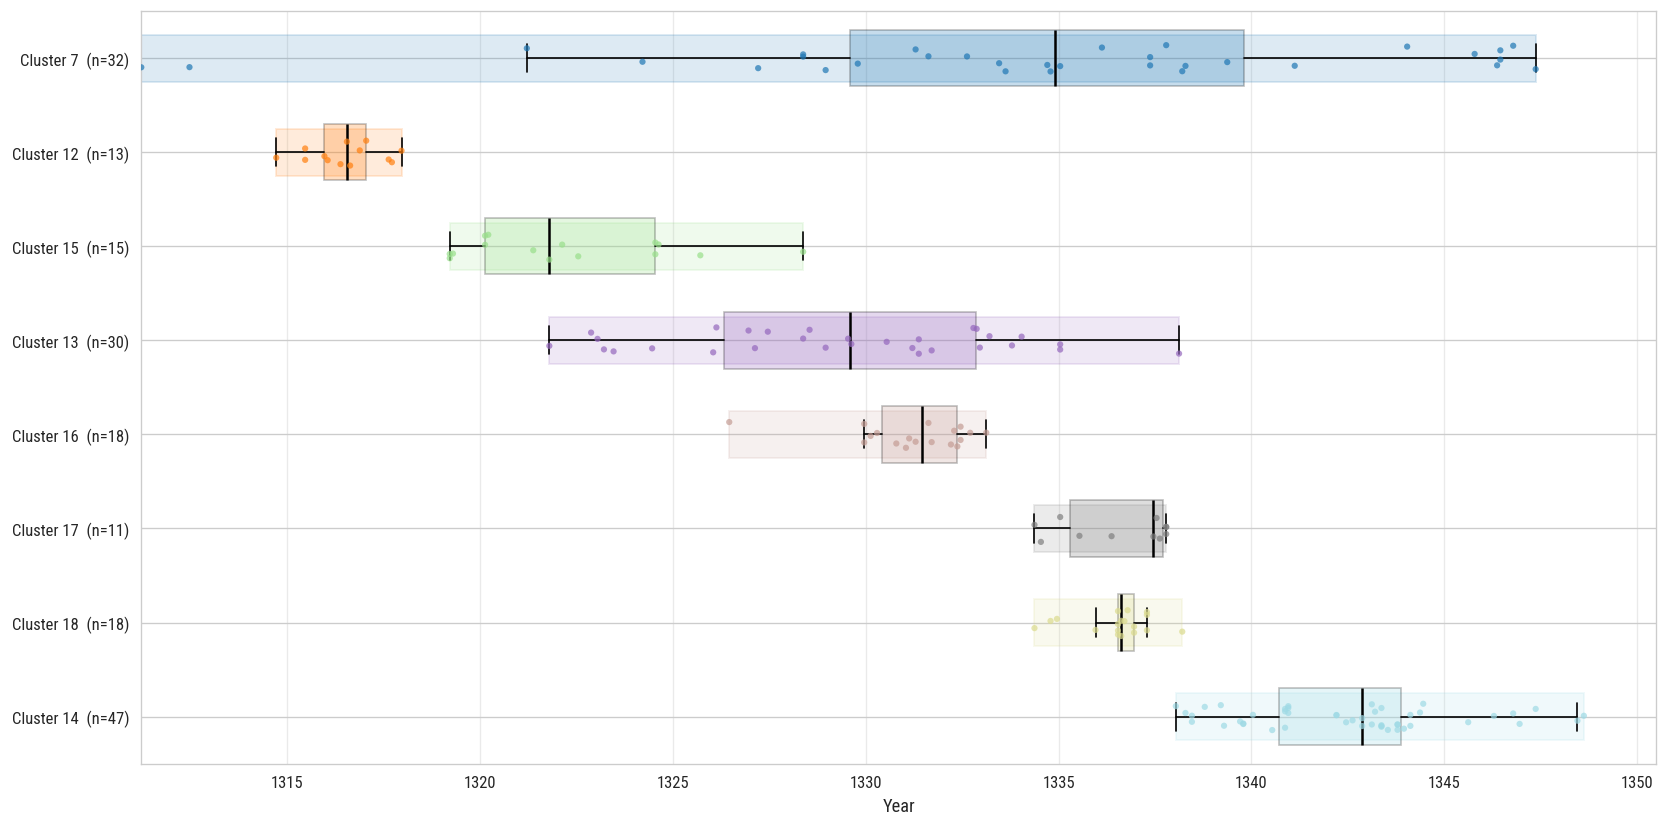

In [18]:
plot_hand_range(df, 'R', '../outputs/r-ranges.png')

Hand S:

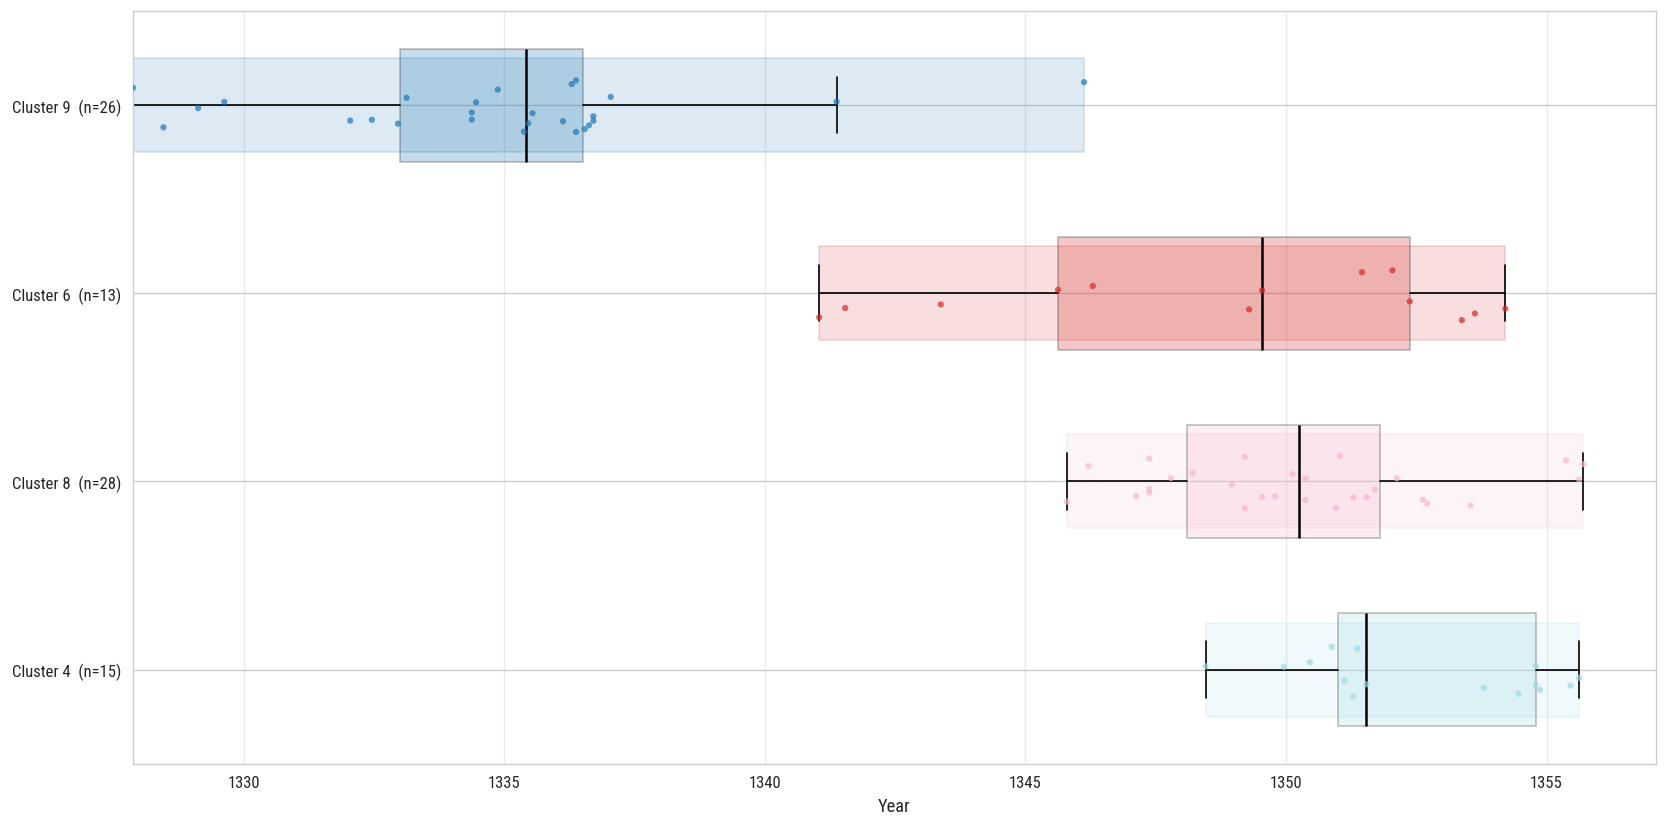

In [19]:
plot_hand_range(df, 'S', '../outputs/s-ranges.png')